In [11]:
import pandas as pad

# Path to the CSV file
file_path = r'E:\2017.Study\Tenx\Week-5\W5.EthioMart-\final_tokens_labels.csv'

# Load the dataset into a DataFrame
dt_ner = pad.read_csv(file_path)

# Display the first few rows to inspect the data
print(dt_ner.head(15))


     Token      Label
0    የህፃናት  B-Product
1    መመገቢያ  I-Product
2       ጡጦ  I-Product
3       ዋጋ    B-PRICE
4      400    I-PRICE
5       ብር    I-PRICE
6      ውስን          O
7       ፍሬ          O
8       ነው          O
9      ያለው          O
10    አድራሻ          O
11  ቁ1መገናኛ      B-LOC
12    መሰረት      I-LOC
13     ደፋር      I-LOC
14      ሞል      I-LOC


In [12]:
from transformers import XLMRobertaTokenizer, XLMRobertaForTokenClassification
import torch

# Load the tokenizer and model
tokenizer = XLMRobertaTokenizer.from_pretrained("xlm-roberta-base")
model = XLMRobertaForTokenClassification.from_pretrained("xlm-roberta-base", num_labels=7)  # Assuming 5 unique labels

# Extract tokens and labels from the dataset
tokens = dt_ner['Token'].tolist()
labels = dt_ner['Label'].tolist()

# Tokenize the text data
tokenized_inputs = tokenizer(tokens, return_tensors="pt", padding=True, truncation=True, is_split_into_words=True)

# Convert labels to a numerical format (we will need a label map for this)
unique_labels = list(set(labels))  # Create a set of unique labels
label_map = {label: idx for idx, label in enumerate(unique_labels)}

# Convert the 'Label' column to integers using the label map
numerical_labels = [label_map[label] for label in labels]

# Check tokenized inputs and corresponding labels
print("Tokenized Inputs:", tokenized_inputs['input_ids'])
print("Labels:", numerical_labels)
 

c:\Users\ethio\Desktop\pyapp\myenv\Lib\site-packages\transformers\tokenization_utils_base.py:1617: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be deprecated in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Some weights of XLMRobertaForTokenClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Tokenized Inputs: tensor([[     0, 114866,  29307,  32465,      6, 149322,   5430,  33609,      6,
          23380,  27339,  80667,   4082,  35648,      6, 100579,    548,  29831,
          13199,   3053,  23683, 140042,  47885,    418,   6231,  60014,   9171,
          88827,  21368, 191973,  45694,   2202,      6, 115742,      6,  31531,
           5653, 137526,  47885,    836,    910,  47885,    304,  60204,   4059,
           4047,      6, 186668, 221847,      6,   3851,  71429,    454,   3348,
          13851,   2010,    454,  47825,   5040,    454,  49334,  29307,    106,
           9171,      6,  31531,   5653,      6,  14414,   5653,  47885,    106,
          36225,   2510,   4046, 197742,   4015,    483,   3882, 158332, 161025,
              6,  60204,   4059,   4047, 145960,    548,  15741,   4722,  16064,
           2681,  71025,   5757,    728,  13253,   9039,   7872,   2934, 169422,
          91602,  16333, 124449, 243084,    623,  17680,  10824,  70317,    816,
          

In [15]:
# Make Predictions
with torch.no_grad():
    outputs = model(**encoding)  # Pass the encoded tokens directly
    logits = outputs.logits  # Access the logits directly from the outputs

# Convert logits to predicted labels
predicted_labels = torch.argmax(logits, dim=2)  # Get the predicted class indices
predicted_labels_list = predicted_labels.cpu().numpy()  # Move to CPU if needed

# Map predicted label ids back to label names
id_to_label = {v: k for k, v in label_to_id.items()}
predicted_labels_mapped = [[id_to_label[label] for label in predicted_label] for predicted_label in predicted_labels_list]

# View predicted labels
print("Predicted labels:", predicted_labels_mapped)




Predicted labels: [['B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Product', 'B-Pr

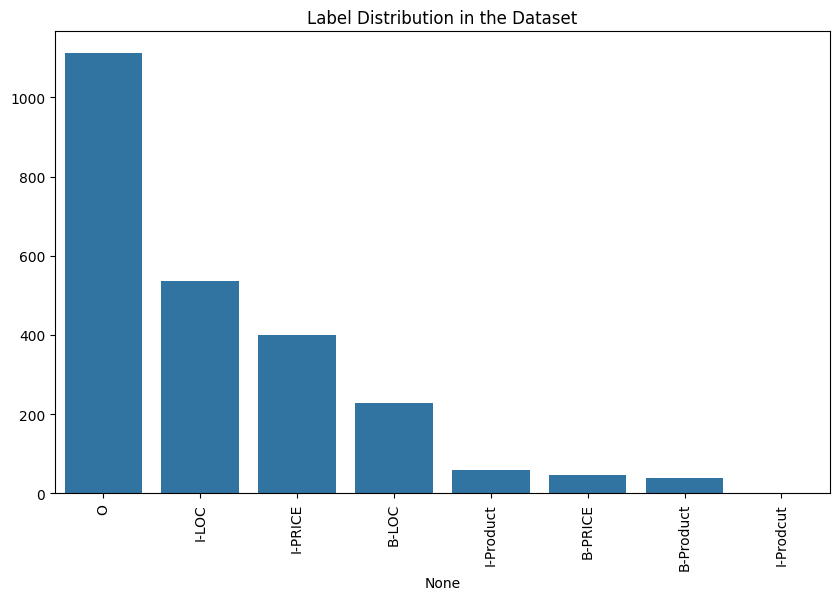

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your labels are in a list called 'all_labels'
label_counts = pd.Series(labels).value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title('Label Distribution in the Dataset')
plt.xticks(rotation=90)
plt.show()


In [21]:
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(labels), y=labels)


In [26]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
labels = np.array([...])  
class_weights = compute_class_weight('balanced', classes=np.unique(labels), y=labels)
class_weights = torch.tensor(class_weights, dtype=torch.float)


In [27]:
import torch.nn as nn

# Define your loss function using class weights
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Or if you are using Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean', class_weights=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        self.class_weights = class_weights

    def forward(self, inputs, targets):
        BCE_loss = nn.functional.cross_entropy(inputs, targets, weight=self.class_weights, reduction='none')
        targets = nn.functional.one_hot(targets, num_classes=inputs.size(1)).float()  # One-hot encode targets
        loss = self.alpha * (1 - inputs.softmax(dim=1)) ** self.gamma * BCE_loss
        
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss

# Use the custom focal loss in your model with class weights
criterion = FocalLoss(class_weights=class_weights)


In [ ]:
import torch.optim as optim

# Define your model, optimizer, and criterion
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)

        # Calculate loss using class weights
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}')
